In [1]:
import pandas as pd
import numpy as np

orders = pd.read_csv("../data/processed/orders.csv")
deliveries = pd.read_csv("../data/processed/deliveries.csv")

print("Orders shape:", orders.shape)
print("Deliveries shape:", deliveries.shape)

print("\nOrders columns:")
print(orders.columns.tolist())

print("\nDeliveries columns:")
print(deliveries.columns.tolist())

display(orders.head())
display(deliveries.head())

Orders shape: (5000, 6)
Deliveries shape: (4075, 6)

Orders columns:
['order_id', 'customer_id', 'restaurant_id', 'order_time', 'order_value', 'status']

Deliveries columns:
['delivery_id', 'order_id', 'courier_id', 'pickup_time', 'delivery_duration', 'delivery_time']


,order_id,customer_id,restaurant_id,order_time,order_value,status
0,10001,318,123,2025-05-26 23:05:00,1067.20,Completed
1,10002,843,101,2025-09-29 06:00:00,991.14,Cancelled
2,10003,36,134,2025-02-02 14:29:00,983.60,Completed
3,10004,447,123,2025-11-26 01:47:00,389.39,Cancelled
4,10005,801,139,2025-07-08 04:12:00,911.09,Completed


,delivery_id,order_id,courier_id,pickup_time,delivery_duration,delivery_time
0,20001,10001,576,2025-05-26 23:25:00,64.0,2025-05-27 00:29:00
1,20002,10003,558,2025-02-02 14:51:00,84.0,2025-02-02 16:15:00
2,20003,10005,512,2025-07-08 04:21:00,23.0,2025-07-08 04:44:00
3,20004,10006,573,2025-08-07 12:31:00,20.0,2025-08-07 12:51:00
4,20005,10007,508,2025-03-11 03:17:00,65.0,2025-03-11 04:22:00


In [2]:
# 1. Inspect data quality
print("Orders missing values:")
display(orders.isnull().sum())

print("\nDeliveries missing values:")
display(deliveries.isnull().sum())

print("\nOrder status distribution:")
display(orders["status"].value_counts())

print("\nDelivery duration summary:")
display(deliveries["delivery_duration"].describe())

print("\nDuplicate order IDs in orders:", orders["order_id"].duplicated().sum())
print("Duplicate order IDs in deliveries:", deliveries["order_id"].duplicated().sum())

Orders missing values:


order_id         0
customer_id      0
restaurant_id    0
order_time       0
order_value      0
status           0
dtype: int64


Deliveries missing values:


delivery_id          0
order_id             0
courier_id           0
pickup_time          0
delivery_duration    0
delivery_time        0
dtype: int64


Order status distribution:


status
Completed      4075
Cancelled       616
In Progress     309
Name: count, dtype: int64


Delivery duration summary:


count    4075.000000
mean       53.417178
std        22.143243
min        15.000000
25%        34.000000
50%        54.000000
75%        73.000000
max        90.000000
Name: delivery_duration, dtype: float64


Duplicate order IDs in orders: 0
Duplicate order IDs in deliveries: 0


In [3]:
# Convert timestamps to datetime
orders["order_time"] = pd.to_datetime(orders["order_time"], errors="coerce")
deliveries["pickup_time"] = pd.to_datetime(deliveries["pickup_time"], errors="coerce")
deliveries["delivery_time"] = pd.to_datetime(deliveries["delivery_time"], errors="coerce")

# Keep completed orders
completed_orders = orders[orders["status"] == "Completed"].copy()

# Merge order and delivery information
df = completed_orders.merge(
    deliveries,
    on="order_id",
    how="inner",
    validate="one_to_one"
)

print("Prepared dataset shape:", df.shape)
display(df.head())

Prepared dataset shape: (4075, 11)


,order_id,customer_id,restaurant_id,order_time,order_value,status,delivery_id,courier_id,pickup_time,delivery_duration,delivery_time
0,10001,318,123,2025-05-26 23:05:00,1067.20,Completed,20001,576,2025-05-26 23:25:00,64.0,2025-05-27 00:29:00
1,10003,36,134,2025-02-02 14:29:00,983.60,Completed,20002,558,2025-02-02 14:51:00,84.0,2025-02-02 16:15:00
2,10005,801,139,2025-07-08 04:12:00,911.09,Completed,20003,512,2025-07-08 04:21:00,23.0,2025-07-08 04:44:00
3,10006,953,131,2025-08-07 12:17:00,975.75,Completed,20004,573,2025-08-07 12:31:00,20.0,2025-08-07 12:51:00
4,10007,252,140,2025-03-11 03:04:00,898.57,Completed,20005,508,2025-03-11 03:17:00,65.0,2025-03-11 04:22:00


In [4]:
df["calculated_duration"] = (
    df["delivery_time"] - df["pickup_time"]
).dt.total_seconds() / 60

df["duration_difference"] = (
    df["delivery_duration"] - df["calculated_duration"]
).abs()

print("Stored duration summary:")
display(df["delivery_duration"].describe())

print(
    "Records where stored and calculated durations differ "
    "by more than 1 minute:",
    (df["duration_difference"] > 1).sum()
)

display(
    df[[
        "order_id",
        "pickup_time",
        "delivery_time",
        "delivery_duration",
        "calculated_duration"
    ]].head()
)

Stored duration summary:


count    4075.000000
mean       53.417178
std        22.143243
min        15.000000
25%        34.000000
50%        54.000000
75%        73.000000
max        90.000000
Name: delivery_duration, dtype: float64

Records where stored and calculated durations differ by more than 1 minute: 0


,order_id,pickup_time,delivery_time,delivery_duration,calculated_duration
0,10001,2025-05-26 23:25:00,2025-05-27 00:29:00,64.0,64.0
1,10003,2025-02-02 14:51:00,2025-02-02 16:15:00,84.0,84.0
2,10005,2025-07-08 04:21:00,2025-07-08 04:44:00,23.0,23.0
3,10006,2025-08-07 12:31:00,2025-08-07 12:51:00,20.0,20.0
4,10007,2025-03-11 03:17:00,2025-03-11 04:22:00,65.0,65.0


In [5]:
# Feature engineering
df["order_hour"] = df["order_time"].dt.hour
df["order_day"] = df["order_time"].dt.dayofweek
df["is_weekend"] = (
    df["order_day"] >= 5
).astype(int)
df["order_month"] = df["order_time"].dt.month

# Create time-of-day categories
def get_time_period(hour):
    if 5 <= hour < 12:
        return "Morning"
    elif 12 <= hour < 17:
        return "Afternoon"
    elif 17 <= hour < 21:
        return "Evening"
    else:
        return "Night"

df["time_period"] = df["order_hour"].apply(get_time_period)

display(
    df[[
        "order_time",
        "order_hour",
        "order_day",
        "is_weekend",
        "order_month",
        "time_period",
        "delivery_duration"
    ]].head()
)

/tmp/ipykernel_3212440/3410968609.py:3: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["order_day"] = df["order_time"].dt.dayofweek


,order_time,order_hour,order_day,is_weekend,order_month,time_period,delivery_duration
0,2025-05-26 23:05:00,23,0,0,5,Night,64.0
1,2025-02-02 14:29:00,14,6,1,2,Afternoon,84.0
2,2025-07-08 04:12:00,4,1,0,7,Night,23.0
3,2025-08-07 12:17:00,12,3,0,8,Afternoon,20.0
4,2025-03-11 03:04:00,3,1,0,3,Night,65.0


In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

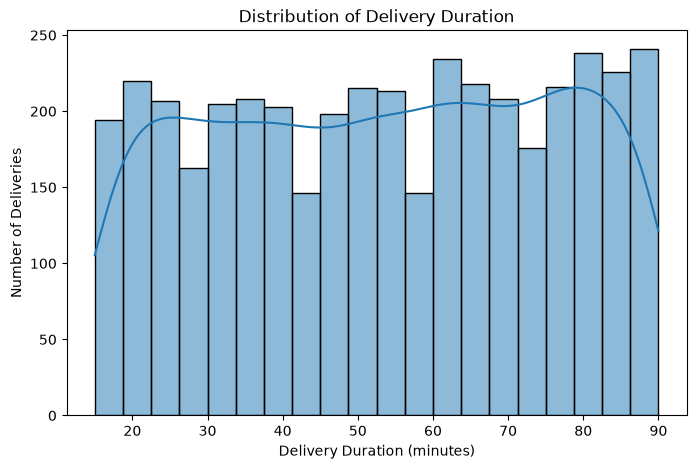

In [7]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="delivery_duration",
    bins=20,
    kde=True
)

plt.title("Distribution of Delivery Duration")
plt.xlabel("Delivery Duration (minutes)")
plt.ylabel("Number of Deliveries")
plt.show()

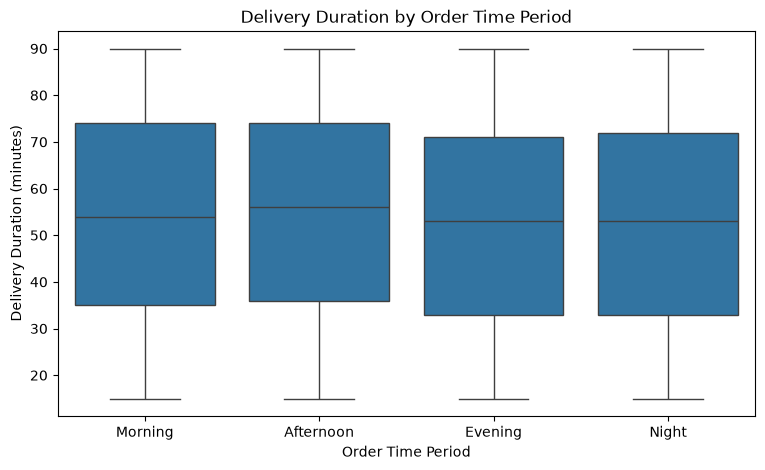

In [8]:
period_order = [
    "Morning", "Afternoon", "Evening", "Night"
]

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="time_period",
    y="delivery_duration",
    order=period_order
)

plt.title("Delivery Duration by Order Time Period")
plt.xlabel("Order Time Period")
plt.ylabel("Delivery Duration (minutes)")
plt.show()

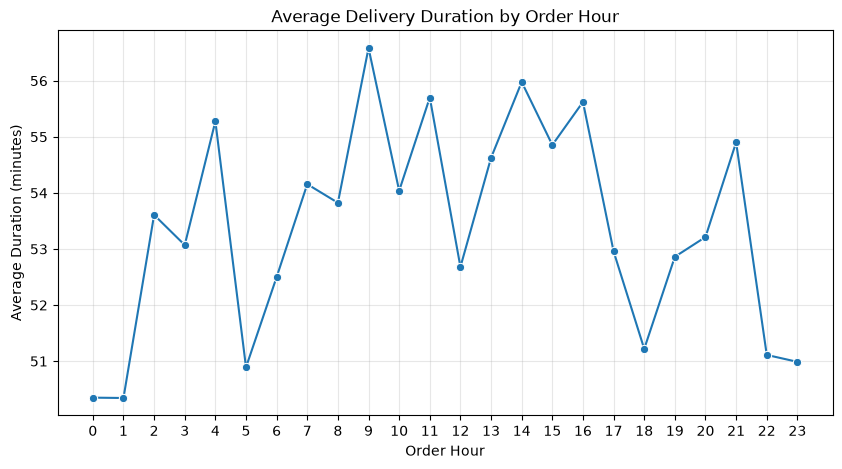

In [9]:
hourly_duration = (
    df.groupby("order_hour")["delivery_duration"]
      .mean()
      .reset_index()
)

plt.figure(figsize=(10, 5))

sns.lineplot(
    data=hourly_duration,
    x="order_hour",
    y="delivery_duration",
    marker="o"
)

plt.xticks(range(24))
plt.title("Average Delivery Duration by Order Hour")
plt.xlabel("Order Hour")
plt.ylabel("Average Duration (minutes)")
plt.grid(True, alpha=0.3)
plt.show()

In [10]:
period_summary = (
    df.groupby("time_period")
      .agg(
          total_deliveries=("delivery_duration", "count"),
          avg_duration=("delivery_duration", "mean"),
          median_duration=("delivery_duration", "median"),
          min_duration=("delivery_duration", "min"),
          max_duration=("delivery_duration", "max")
      )
      .round(2)
      .reindex(["Morning", "Afternoon", "Evening", "Night"])
)

display(period_summary)

,total_deliveries,avg_duration,median_duration,min_duration,max_duration
time_period,,,,,
Morning,1212,53.92,54.0,15.0,90.0
Afternoon,856,54.79,56.0,15.0,90.0
Evening,655,52.56,53.0,15.0,90.0
Night,1352,52.51,53.0,15.0,90.0


In [11]:
weekend_summary = (
    df.groupby("is_weekend")
      .agg(
          total_deliveries=("delivery_duration", "count"),
          avg_duration=("delivery_duration", "mean"),
          median_duration=("delivery_duration", "median")
      )
      .round(2)
      .rename(index={0: "Weekday", 1: "Weekend"})
)

display(weekend_summary)

,total_deliveries,avg_duration,median_duration
is_weekend,,,
Weekday,2878,53.41,54.0
Weekend,1197,53.43,54.0


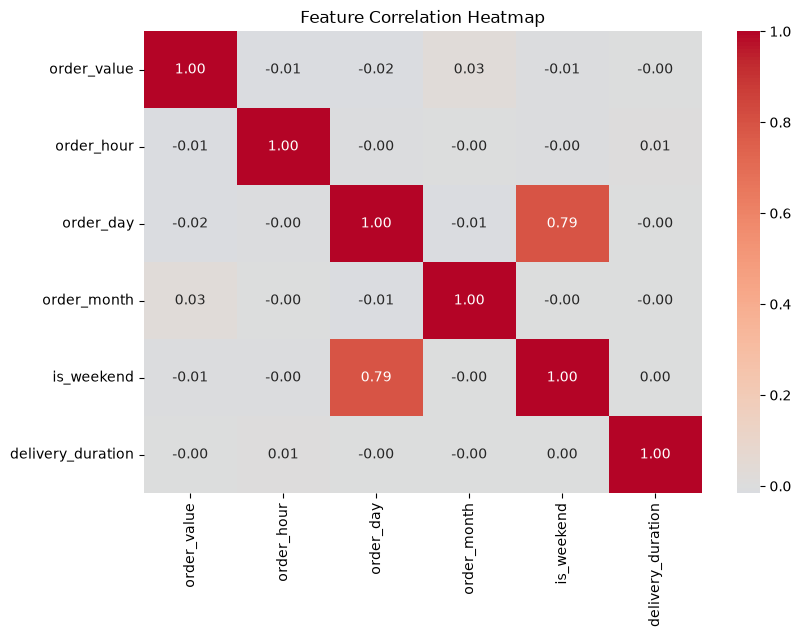

In [14]:
# Numeric feature correlations
corr_cols = [
    "order_value",
    "order_hour",
    "order_day",
    "order_month",
    "is_weekend",
    "delivery_duration"
]

plt.figure(figsize=(9, 6))

sns.heatmap(
    df[corr_cols].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Feature Correlation Heatmap")
plt.show()

In [15]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Select features available at order placement
features = [
    "order_value",
    "order_hour",
    "order_day",
    "order_month",
    "is_weekend",
    "time_period"
]

X = df[features].copy()
y = df["delivery_duration"].copy()

# Encode categorical feature
X = pd.get_dummies(
    X,
    columns=["time_period"],
    drop_first=True,
    dtype=int
)

# Train-test split: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Target shape:", y.shape)
print("\nModel features:", X.columns.tolist())

Training features: (3260, 8)
Testing features: (815, 8)
Target shape: (4075,)

Model features: ['order_value', 'order_hour', 'order_day', 'order_month', 'is_weekend', 'time_period_Evening', 'time_period_Morning', 'time_period_Night']


In [16]:
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

lr_pred = lr_model.predict(X_test)

lr_mae = mean_absolute_error(y_test, lr_pred)
lr_rmse = np.sqrt(mean_squared_error(y_test, lr_pred))
lr_r2 = r2_score(y_test, lr_pred)

print("Linear Regression Results")
print("-------------------------")
print("MAE:", round(lr_mae, 2), "minutes")
print("RMSE:", round(lr_rmse, 2), "minutes")
print("R²:", round(lr_r2, 3))

Linear Regression Results
-------------------------
MAE: 18.83 minutes
RMSE: 21.75 minutes
R²: -0.0


In [17]:
rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    min_samples_leaf=3,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest Results")
print("---------------------")
print("MAE:", round(rf_mae, 2), "minutes")
print("RMSE:", round(rf_rmse, 2), "minutes")
print("R²:", round(rf_r2, 3))

Random Forest Results
---------------------
MAE: 19.43 minutes
RMSE: 22.73 minutes
R²: -0.092


In [18]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)

baseline_pred = baseline.predict(X_test)

comparison = pd.DataFrame({
    "Model": ["Mean Baseline", "Linear Regression", "Random Forest"],
    "MAE": [
        mean_absolute_error(y_test, baseline_pred),
        mean_absolute_error(y_test, lr_pred),
        mean_absolute_error(y_test, rf_pred)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, baseline_pred)),
        np.sqrt(mean_squared_error(y_test, lr_pred)),
        np.sqrt(mean_squared_error(y_test, rf_pred))
    ],
    "R2": [
        r2_score(y_test, baseline_pred),
        r2_score(y_test, lr_pred),
        r2_score(y_test, rf_pred)
    ]
})

display(comparison.round(3))

,Model,MAE,RMSE,R2
0,Mean Baseline,18.845,21.748,-0.000
1,Linear Regression,18.834,21.748,-0.000
2,Random Forest,19.431,22.726,-0.092


,Feature,Importance
0,order_value,0.493554
3,order_month,0.172060
1,order_hour,0.170502
2,order_day,0.121584
4,is_weekend,0.012993
6,time_period_Morning,0.012414
7,time_period_Night,0.008688
5,time_period_Evening,0.008205


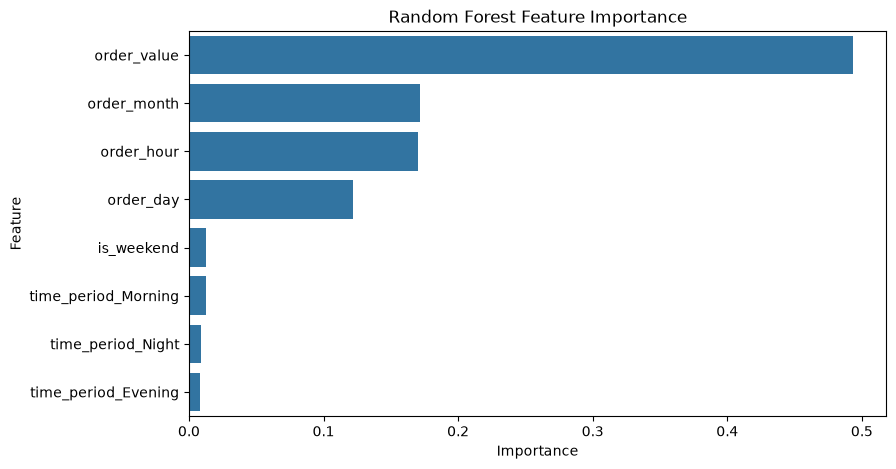

In [19]:
importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False)

display(importance)

plt.figure(figsize=(9, 5))
sns.barplot(data=importance, x="Importance", y="Feature")
plt.title("Random Forest Feature Importance")
plt.show()

### Model Evaluation — Observations, Transitions, and Conclusions

#### Observations
- The Mean Baseline achieved an MAE of 18.845 minutes and RMSE of 21.748 minutes.
- Linear Regression achieved an MAE of 18.834 minutes and RMSE of 21.748 minutes, providing only a negligible improvement over the baseline.
- Random Forest achieved an MAE of 19.431 minutes, RMSE of 22.726 minutes, and R² of -0.092.
- Order value had the highest Random Forest feature importance at approximately 49.36%, followed by order month and order hour.
- All models showed limited predictive performance with the current feature set.

#### Transitions
The initial regression models were evaluated against a mean-prediction baseline to establish whether the selected features added meaningful predictive value. Random Forest feature importance was also examined to understand which features influenced its predictions.

#### Conclusions
Linear Regression slightly outperformed the mean baseline, while Random Forest performed worse on the test set. The results suggest that order value and time-based features alone are insufficient to accurately predict delivery duration. Further improvement would require more informative predictors, such as delivery distance, restaurant preparation time, traffic conditions, weather, or courier availability, if those data can be collected. These potential features are recommendations for future data collection, not variables currently available in the dataset.

The models should not yet be used for operational delivery-time estimates. Their performance should be reassessed after adding relevant predictors and validating against representative real-world delivery data.

In [20]:
results = comparison.copy()
results.to_csv(
    "../reports/day4_model_comparison.csv",
    index=False
)

print("Model comparison saved successfully.")

Model comparison saved successfully.
